# Lab 03: Architectures and their costs
Compare the prescribed MLP, CNN and patch-attention models on Fashion-MNIST. Run all cells in order using Python 3.11.8 and the course environment. Data are downloaded to the ignored repository-level `data/` directory. All experiment code is in this notebook.

The exact layer specifications are used even though their parameter counts do not all fit the stated 100k–150k target. This inconsistency is reported rather than changing the models.

In [1]:
import os
from pathlib import Path
import random
import csv
import json
import platform
import importlib.metadata as metadata
import time
import statistics

# Keep CPU thread overhead bounded for the small models; applied before model execution.
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("MKL_NUM_THREADS", "2")
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from torchinfo import summary
from thop import profile
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "lab03":
    ROOT = ROOT.parent
assert (ROOT / "requirements.txt").is_file(), "Start from the repository root or lab03."
OUT = ROOT / "lab03" / "results"
OUT.mkdir(parents=True, exist_ok=True)
DATA = ROOT / "data"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(2)
# Disable fused inference paths so profiling hooks observe the same explicit operations.
torch.backends.mha.set_fastpath_enabled(False)

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything()
versions = [f"Python: {platform.python_version()} (required: 3.11.8)"]
for line in (ROOT / "requirements.txt").read_text().splitlines():
    if "==" in line and not line.startswith("#"):
        name, expected = line.split("==", 1)
        try:
            actual = metadata.version(name)
        except metadata.PackageNotFoundError:
            actual = "NOT INSTALLED"
        versions.append(f"{name}: {actual} (required: {expected})")
versions += [f"Device: {DEVICE}", f"CPU: {platform.processor()}",
             f"PyTorch CPU threads: {torch.get_num_threads()}", "MHA fastpath: disabled"]
(OUT / "versions.txt").write_text("\n".join(versions) + "\n", encoding="utf-8")
print("\n".join(versions))

def write_csv(name, rows):
    with (OUT / name).open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=rows[0].keys())
        writer.writeheader()
        writer.writerows(rows)

Python: 3.11.8 (required: 3.11.8)
numpy: 1.26.4 (required: 1.26.4)
pandas: 2.2.2 (required: 2.2.2)
scikit-learn: 1.5.0 (required: 1.5.0)
scipy: 1.13.1 (required: 1.13.1)
matplotlib: 3.9.0 (required: 3.9.0)
seaborn: 0.13.2 (required: 0.13.2)
torch: 2.3.1 (required: 2.3.1)
torchvision: 0.18.1 (required: 0.18.1)
torchinfo: 1.8.0 (required: 1.8.0)
thop: 0.1.1-2209072238 (required: 0.1.1.post2209072238)
onnx: 1.16.1 (required: 1.16.1)
onnxruntime: 1.18.0 (required: 1.18.0)
mlflow: 2.14.1 (required: 2.14.1)
memory-profiler: 0.61.0 (required: 0.61.0)
psutil: 5.9.8 (required: 5.9.8)
codecarbon: 2.4.2 (required: 2.4.2)
fastapi: 0.111.0 (required: 0.111.0)
uvicorn: 0.30.1 (required: 0.30.1)
pytest: 8.2.2 (required: 8.2.2)
httpx: 0.27.0 (required: 0.27.0)
locust: 2.28.0 (required: 2.28.0)
requests: 2.32.3 (required: 2.32.3)
pyarrow: 15.0.2 (required: 15.0.2)
joblib: 1.4.2 (required: 1.4.2)
tqdm: 4.66.4 (required: 4.66.4)
Device: cpu
CPU: Intel64 Family 6 Model 186 Stepping 3, GenuineIntel
PyTorch

C:\Users\maria\Desktop\university\ML_73952\lab01\.venv\Lib\site-packages\torch\cuda\__init__.py:56: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


## 1. Dataset and split
Use the official 60,000-image training set, deterministically split into 55,000 training and 5,000 validation examples. The official 10,000-image test set is kept separate. Normalize tensors with mean 0.2860 and standard deviation 0.3530. Each model receives the same shuffled batch order by resetting the loader generator.

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,)),
])
full_train = datasets.FashionMNIST(root=str(DATA), train=True, download=True, transform=transform)
test_set = datasets.FashionMNIST(root=str(DATA), train=False, download=True, transform=transform)
train_set, val_set = random_split(full_train, [55000, 5000], generator=torch.Generator().manual_seed(42))
assert set(train_set.indices).isdisjoint(val_set.indices)
assert len(test_set) == 10000

def training_loader():
    return DataLoader(train_set, batch_size=128, shuffle=True, num_workers=0,
                      generator=torch.Generator().manual_seed(42))

val_loader = DataLoader(val_set, batch_size=128, shuffle=False, num_workers=0)
test_loader = DataLoader(test_set, batch_size=128, shuffle=False, num_workers=0)
print(f"Train: {len(train_set)}; validation: {len(val_set)}; test: {len(test_set)}")
print("Batch shape:", next(iter(val_loader))[0].shape)

Extracting C:\Users\maria\Desktop\university\ML_73952\data\FashionMNIST\raw\train-images-idx3-ubyte.gz to C:\Users\maria\Desktop\university\ML_73952\data\FashionMNIST\raw

Extracting C:\Users\maria\Desktop\university\ML_73952\data\FashionMNIST\raw\train-labels-idx1-ubyte.gz to C:\Users\maria\Desktop\university\ML_73952\data\FashionMNIST\raw

Extracting C:\Users\maria\Desktop\university\ML_73952\data\FashionMNIST\raw\t10k-images-idx3-ubyte.gz to C:\Users\maria\Desktop\university\ML_73952\data\FashionMNIST\raw

Extracting C:\Users\maria\Desktop\university\ML_73952\data\FashionMNIST\raw\t10k-labels-idx1-ubyte.gz to C:\Users\maria\Desktop\university\ML_73952\data\FashionMNIST\raw

Train: 55000; validation: 5000; test: 10000
Batch shape: torch.Size([128, 1, 28, 28])


100%|##########| 5148/5148 [00:00<?, ?it/s]


## 2. Prescribed architectures
The MLP treats all pixels as a vector. The CNN reuses 3×3 filters across local image regions. The attention model reshapes each image into 16 non-overlapping 7×7 patches, projects each 49-value patch to 64 dimensions, applies two four-head Transformer encoder layers and mean-pools the tokens.

The Transformer uses PyTorch defaults for ReLU, dropout 0.1 and LayerNorm epsilon. No positional embeddings or class token are added, since neither is specified. This makes the attention model invariant to permutations of whole patches and limits its spatial information; local pixel positions within each patch are still retained.

In [3]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(), nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 10))
    def forward(self, x):
        return self.network(x)

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(32 * 7 * 7, 10))
    def forward(self, x):
        return self.network(x)

class PatchAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.projection = nn.Linear(49, 64)
        layer = nn.TransformerEncoderLayer(d_model=64, nhead=4,
                    dim_feedforward=128, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=2, enable_nested_tensor=False)
        self.classifier = nn.Linear(64, 10)
    def forward(self, x):
        batch = x.shape[0]
        patches = x.reshape(batch, 1, 4, 7, 4, 7).permute(0, 2, 4, 1, 3, 5)
        tokens = patches.reshape(batch, 16, 49)
        tokens = self.encoder(self.projection(tokens))
        return self.classifier(tokens.mean(dim=1))

FACTORIES = {"MLP": MLP, "CNN": CNN, "Attention": PatchAttention}
parameter_rows = []
summaries = []
for name, factory in FACTORIES.items():
    seed_everything()
    model = factory().eval()
    assert model(torch.zeros(2, 1, 28, 28)).shape == (2, 10)
    info = summary(model, input_size=(1, 1, 28, 28), device="cpu", verbose=0)
    count = sum(p.numel() for p in model.parameters())
    assert count == info.total_params
    parameter_rows.append(dict(model=name, parameters=count, target_100k_150k=100000 <= count <= 150000))
    summaries.append(f"{name}\n{info}")
    print(name, "parameters:", count)
(OUT / "model_summaries.txt").write_text("\n\n".join(summaries), encoding="utf-8")


MLP parameters: 235146
CNN parameters: 20490
Attention parameters: 70794


## 3. Hand calculations and profiler comparison
Count a multiply and an addition as two FLOPs, excluding biases, activation functions, softmax, normalization, residual additions and pooling in the hand estimates.

* MLP first layer: 2×784×256 = **401,408 FLOPs**. All three linear layers: 2×(784×256 + 256×128 + 128×10) = **469,504 FLOPs/image**.
* CNN first convolution: 2×3×3×1×16×28×28 = **225,792 FLOPs**. Second convolution: 2×3×3×16×32×14×14 = **1,806,336**; output linear layer: 2×1568×10 = **31,360**. Total: **2,063,488 FLOPs/image**.
* Attention, sequence length S=16 and width d=64: QKV projections cost 2×S×d×3d = **393,216 FLOPs/layer**; QK^T costs 2×S²×d = **32,768**, and multiplication by V costs another **32,768**. Output projection costs **131,072**. The two feedforward linear layers cost **524,288**. One encoder layer therefore costs **1,114,112**; adding two layers, the patch projection (100,352) and classifier (1,280) gives **2,329,856 FLOPs/image**.

THOP normally reports MACs rather than this two-operation FLOP convention. Its default hooks do not fully count `MultiheadAttention`. Compare the default profile with a custom attention hook that counts the four attention matrix products, while the existing linear hooks count patch projection, feedforward layers and classifier. Normalization and other supported operations can introduce smaller differences. Parameter totals come from torchinfo and direct counting, rather than relying on THOP's coverage.

In [4]:
HAND_FLOPS = {
    "MLP": 2 * (784*256 + 256*128 + 128*10),
    "CNN": 2 * (3*3*1*16*28*28 + 3*3*16*32*14*14 + 1568*10),
    "Attention": 2 * 16*49*64 + 2 * (2*16*64*3*64 + 4*16*16*64 + 2*16*64*64 + 4*16*64*128) + 2*64*10,
}

def count_attention(module, inputs, output):
    query = inputs[0]
    batch, seq, dim = query.shape
    # Q,K,V projections + QK^T + attention@V + output projection, in MACs.
    macs = batch * (3*seq*dim*dim + 2*seq*seq*dim + seq*dim*dim)
    module.total_ops += torch.DoubleTensor([macs])

cost_rows = []
for name, factory in FACTORIES.items():
    sample = torch.zeros(1, 1, 28, 28)
    default_macs, _ = profile(factory().eval(), inputs=(sample,), verbose=False)
    supported_macs, _ = profile(factory().eval(), inputs=(sample,),
                    custom_ops={nn.MultiheadAttention: count_attention}, verbose=False)
    row = dict(model=name, hand_matmul_flops=HAND_FLOPS[name],
               thop_default_macs=int(default_macs), thop_supported_macs=int(supported_macs),
               thop_supported_flops_2x=int(2*supported_macs))
    cost_rows.append(row)
    print(row)


{'model': 'MLP', 'hand_matmul_flops': 469504, 'thop_default_macs': 234752, 'thop_supported_macs': 234752, 'thop_supported_flops_2x': 469504}
{'model': 'CNN', 'hand_matmul_flops': 2063488, 'thop_default_macs': 1031744, 'thop_supported_macs': 1031744, 'thop_supported_flops_2x': 2063488}
{'model': 'Attention', 'hand_matmul_flops': 2329856, 'thop_default_macs': 591488, 'thop_supported_macs': 1181312, 'thop_supported_flops_2x': 2362624}


## 4. Five training epochs per model
Use Adam with learning rate 0.001 and cross-entropy on raw logits. Report validation metrics each epoch but evaluate the official test set only for the final epoch-five model. No early stopping or test-based checkpoint selection is used.

In [5]:
@torch.inference_mode()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    correct = 0
    count = 0
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        logits = model(images)
        total_loss += nn.functional.cross_entropy(logits, labels, reduction="sum").item()
        correct += (logits.argmax(1) == labels).sum().item()
        count += labels.numel()
    return total_loss / count, correct / count

trained = {}
history = []
final_rows = []
for name, factory in FACTORIES.items():
    seed_everything()
    model = factory().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loader = training_loader()
    for epoch in range(1, 6):
        model.train()
        total_loss = 0.0
        correct = 0
        count = 0
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = nn.functional.cross_entropy(logits, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * labels.numel()
            correct += (logits.argmax(1) == labels).sum().item()
            count += labels.numel()
        val_loss, val_accuracy = evaluate(model, val_loader)
        row = dict(model=name, epoch=epoch, train_loss=total_loss/count,
                   train_accuracy=correct/count, val_loss=val_loss,
                   val_accuracy=val_accuracy)
        history.append(row)
        write_csv("training_history.csv", history)
        print(f"{name:9s} epoch {epoch}/5: train loss={row['train_loss']:.4f}, "
              f"val accuracy={val_accuracy:.4%}", flush=True)
    test_loss, test_accuracy = evaluate(model, test_loader)
    final_rows.append(dict(model=name, test_loss=test_loss, test_accuracy=test_accuracy))
    trained[name] = model.eval()
    print(f"{name}: final test accuracy={test_accuracy:.4%}", flush=True)

MLP       epoch 1/5: train loss=0.4919, val accuracy=84.2800%
MLP       epoch 2/5: train loss=0.3538, val accuracy=86.2600%
MLP       epoch 3/5: train loss=0.3143, val accuracy=87.1800%
MLP       epoch 4/5: train loss=0.2905, val accuracy=88.0200%
MLP       epoch 5/5: train loss=0.2698, val accuracy=88.1200%
MLP: final test accuracy=87.6400%
CNN       epoch 1/5: train loss=0.5295, val accuracy=84.7600%
CNN       epoch 2/5: train loss=0.3510, val accuracy=87.0000%
CNN       epoch 3/5: train loss=0.3050, val accuracy=88.8000%
CNN       epoch 4/5: train loss=0.2793, val accuracy=88.5800%
CNN       epoch 5/5: train loss=0.2624, val accuracy=89.7600%
CNN: final test accuracy=89.1700%
Attention epoch 1/5: train loss=0.8291, val accuracy=79.6000%
Attention epoch 2/5: train loss=0.5450, val accuracy=80.5600%
Attention epoch 3/5: train loss=0.4784, val accuracy=83.4200%
Attention epoch 4/5: train loss=0.4434, val accuracy=84.1600%
Attention epoch 5/5: train loss=0.4179, val accuracy=84.9400%
At

## 5. Inference latency
Measure model execution on already prepared device tensors, excluding dataset loading and host-to-device copies. Use eval mode and inference mode, one warm-up before each batch-size measurement, then the median of 100 runs for batch 1 and 20 runs for batch 128. Synchronize CUDA before and after each timed call if a GPU is used. Batch latency and amortized per-image latency have different meanings.

In [6]:
def synchronize():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

@torch.inference_mode()
def benchmark(model, images, runs):
    model.eval()
    model(images)
    synchronize()
    samples = []
    for _ in range(runs):
        synchronize()
        start = time.perf_counter_ns()
        model(images)
        synchronize()
        samples.append((time.perf_counter_ns() - start) / 1e6)
    return statistics.median(samples)

images, _ = next(iter(test_loader))
latency_rows = []
for name, model in trained.items():
    for batch_size, runs in ((1, 100), (128, 20)):
        batch = images[:batch_size].to(DEVICE)
        median_ms = benchmark(model, batch, runs)
        row = dict(model=name, batch_size=batch_size, runs=runs, median_batch_ms=median_ms,
                   amortized_image_ms=median_ms/batch_size, images_per_second=batch_size*1000/median_ms)
        latency_rows.append(row)
        print(row)


{'model': 'MLP', 'batch_size': 1, 'runs': 100, 'median_batch_ms': 0.48250000000000004, 'amortized_image_ms': 0.48250000000000004, 'images_per_second': 2072.5388601036266}
{'model': 'MLP', 'batch_size': 128, 'runs': 20, 'median_batch_ms': 2.8332, 'amortized_image_ms': 0.022134375, 'images_per_second': 45178.596639841875}
{'model': 'CNN', 'batch_size': 1, 'runs': 100, 'median_batch_ms': 1.0662500000000001, 'amortized_image_ms': 1.0662500000000001, 'images_per_second': 937.8663540445485}
{'model': 'CNN', 'batch_size': 128, 'runs': 20, 'median_batch_ms': 38.041650000000004, 'amortized_image_ms': 0.29720039062500003, 'images_per_second': 3364.733128032038}
{'model': 'Attention', 'batch_size': 1, 'runs': 100, 'median_batch_ms': 3.3568499999999997, 'amortized_image_ms': 3.3568499999999997, 'images_per_second': 297.8983273008922}
{'model': 'Attention', 'batch_size': 128, 'runs': 20, 'median_batch_ms': 26.146349999999998, 'amortized_image_ms': 0.20426835937499999, 'images_per_second': 4895.5207

## 6. Accuracy/cost trade-offs
Compare the exact prescribed models after equal numbers of epochs, without assuming equal parameter count or equal FLOPs. The latency plot uses single-image latency; the batch-128 measurements remain available in the output table.

Plots saved to C:\Users\maria\Desktop\university\ML_73952\lab03\results
{'model': 'MLP', 'parameters': 235146, 'target_100k_150k': False, 'hand_matmul_flops': 469504, 'thop_default_macs': 234752, 'thop_supported_macs': 234752, 'thop_supported_flops_2x': 469504, 'test_loss': 0.341728399848938, 'test_accuracy': 0.8764, 'batch1_ms': 0.48250000000000004, 'batch1_runs': 100, 'batch1_amortized_image_ms': 0.48250000000000004, 'batch128_ms': 2.8332, 'batch128_runs': 20, 'batch128_amortized_image_ms': 0.022134375}
{'model': 'CNN', 'parameters': 20490, 'target_100k_150k': False, 'hand_matmul_flops': 2063488, 'thop_default_macs': 1031744, 'thop_supported_macs': 1031744, 'thop_supported_flops_2x': 2063488, 'test_loss': 0.29793481857776644, 'test_accuracy': 0.8917, 'batch1_ms': 1.0662500000000001, 'batch1_runs': 100, 'batch1_amortized_image_ms': 1.0662500000000001, 'batch128_ms': 38.041650000000004, 'batch128_runs': 20, 'batch128_amortized_image_ms': 0.29720039062500003}
{'model': 'Attention', 'par

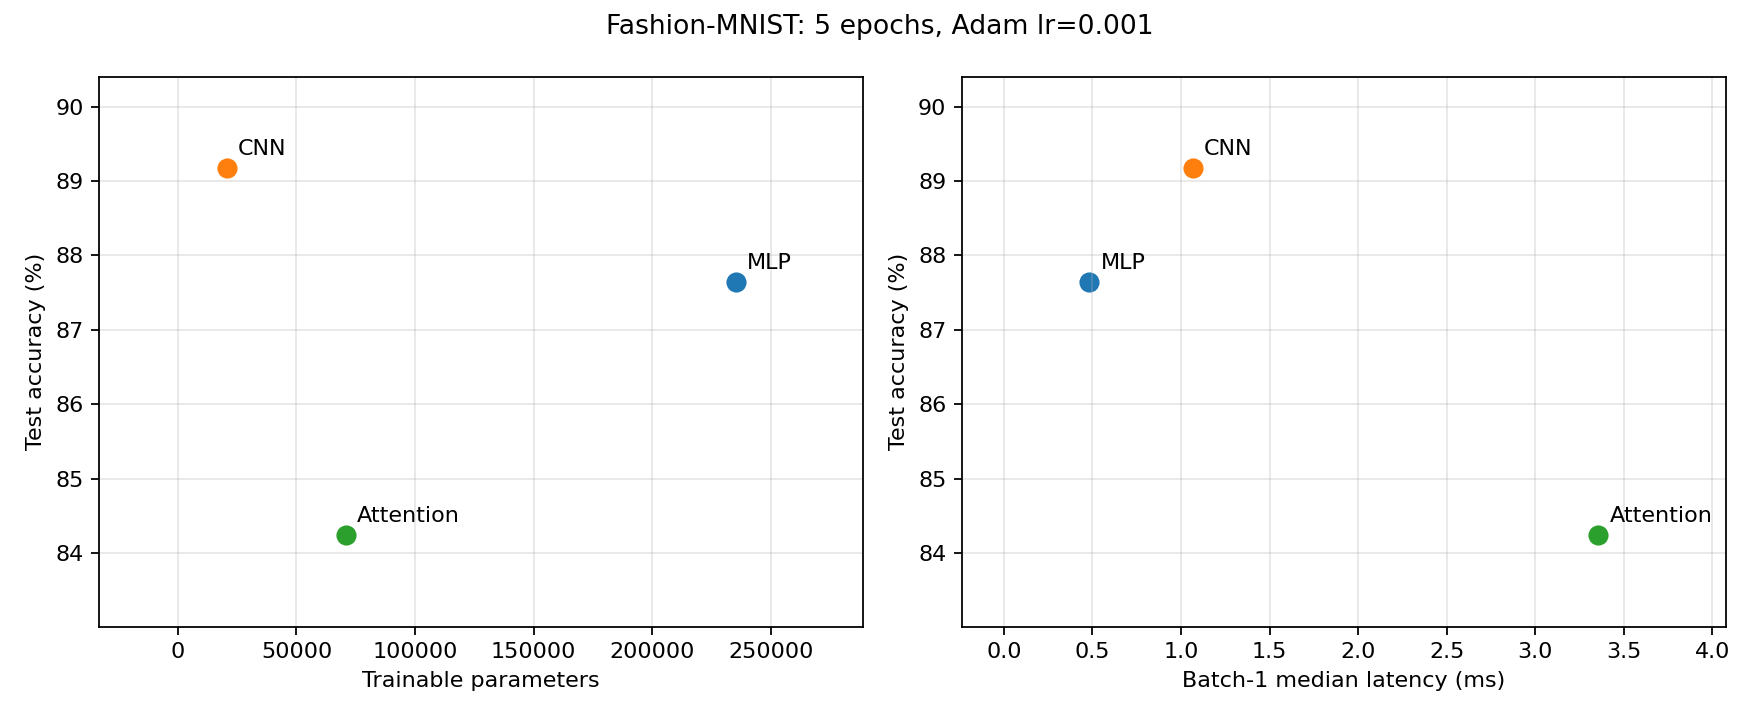

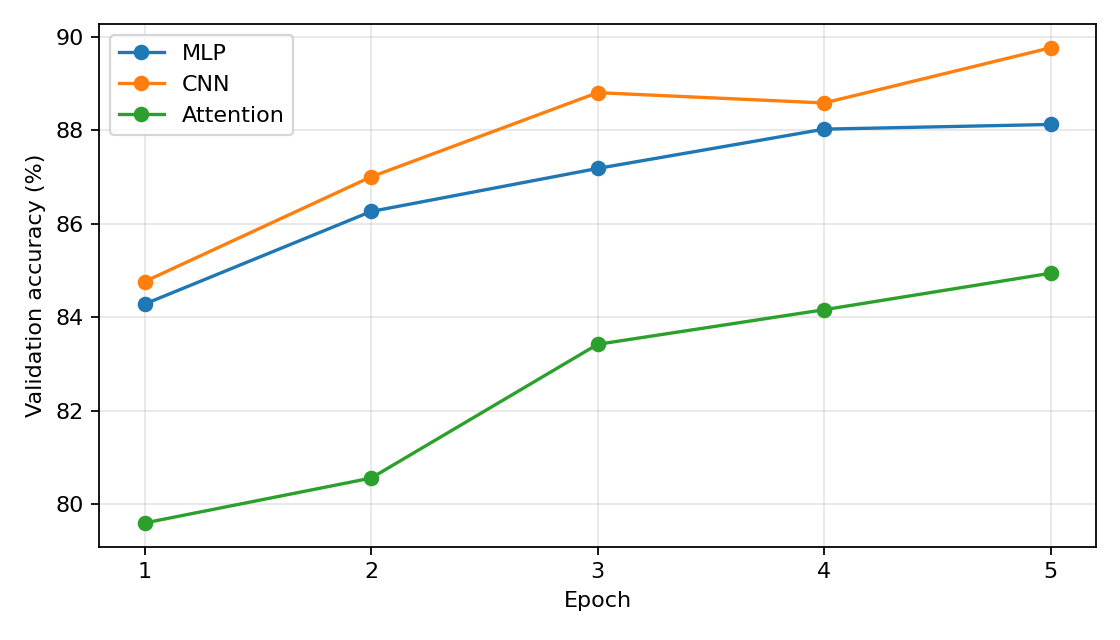

In [7]:
results = []
for accuracy_row in final_rows:
    name = accuracy_row["model"]
    row = dict(next(p for p in parameter_rows if p["model"] == name))
    row.update(next(c for c in cost_rows if c["model"] == name))
    row.update(accuracy_row)
    for batch_size, runs in ((1, 100), (128, 20)):
        measured = next(l for l in latency_rows if l["model"] == name and l["batch_size"] == batch_size)
        row[f"batch{batch_size}_ms"] = measured["median_batch_ms"]
        row[f"batch{batch_size}_runs"] = runs
        row[f"batch{batch_size}_amortized_image_ms"] = measured["amortized_image_ms"]
    results.append(row)
write_csv("measurements.csv", results)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for r in results:
    accuracy_percent = 100*r["test_accuracy"]
    axes[0].scatter(r["parameters"], accuracy_percent, s=65)
    axes[0].annotate(r["model"], (r["parameters"], accuracy_percent), xytext=(5, 6), textcoords="offset points")
    axes[1].scatter(r["batch1_ms"], accuracy_percent, s=65)
    axes[1].annotate(r["model"], (r["batch1_ms"], accuracy_percent), xytext=(5, 6), textcoords="offset points")
axes[0].set_xlabel("Trainable parameters")
axes[1].set_xlabel("Batch-1 median latency (ms)")
for ax in axes:
    ax.set_ylabel("Test accuracy (%)")
    ax.grid(alpha=0.3)
    ax.margins(x=0.25, y=0.25)
fig.suptitle("Fashion-MNIST: 5 epochs, Adam lr=0.001")
fig.tight_layout()
fig.savefig(OUT / "tradeoffs.png", dpi=160)
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 4))
for name in FACTORIES:
    rows = [r for r in history if r["model"] == name]
    ax.plot([r["epoch"] for r in rows], [100*r["val_accuracy"] for r in rows], marker="o", label=name)
ax.set(xlabel="Epoch", ylabel="Validation accuracy (%)", xticks=range(1,6))
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "validation_curves.png", dpi=160)
plt.close(fig)
print("Plots saved to", OUT)
for row in results:
    print(row)
# In Jupyter, display the saved plots inline as well.
try:
    from IPython.display import Image, display
except ImportError:
    pass
else:
    display(Image(filename=str(OUT / "tradeoffs.png")))
    display(Image(filename=str(OUT / "validation_curves.png")))


## Interpretation
MLP layers use dense matrix products, with no explicit locality bias. CNN filters reuse shared weights across neighboring pixels; this greatly reduces parameter storage, while overlapping windows still require substantial computation. Attention shares token projection weights but forms pairwise interactions, whose score/value work grows quadratically with token count. With only 16 patches this term is small, yet token projections, feedforward layers and normalization still incur overhead.

Use the measured tables and plots to identify the practical accuracy/size/latency trade-off. The full report is in `report.md`. The supplied textbook edition places the related material in Chapter 6 (Network Architectures), whereas the lab manual refers to Chapter 4 in another edition.

Measured test accuracy: MLP 87.64%, CNN 89.17%, attention 84.24%. CNN provides the best measured accuracy/parameter trade-off; MLP has the lowest inference latency. The consolidated evidence is in `results/measurements.csv`.
